# Exercises week 43 — solutions

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning, October 19–23, 2026**

This notebook is a complete worked solution of the week-43 set: the
confusion matrix, the ROC curve and the AUC written from the definitions and
checked against `scikit-learn` (exercise 1); MNIST, one digit against the
rest, with the two classifiers of Project 2 (exercise 2); and the ten-class
confusion matrix (exercise 3, optional). The classifiers are the week-41
network (`create_layers`, `feed_forward`, `backpropagation`, `train`,
`predict`) exactly as in the Monday and Tuesday notebooks of weeks 41–43;
your own Project 2 code should give the same numbers if you use the same
seed (2026), initialisation and SGD, and numbers in the same places if you
do not.

The digit of exercise 2 is $d=8$ here (the lecture used $5$); the text says
what changes for another digit. Everything is executed; the numbers quoted
in the text are the ones printed by the cells. Running everything takes
about two minutes with `mnist.npz` next to the notebook (or in
`../BookPrograms/chapter10_convolutional_networks/`).

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics as skm

BLUE, RED, YELLOW, GREY = "#004488", "#BB5566", "#DDAA33", "#777777"
GREEN = "#228833"
np.set_printoptions(precision=4, suppress=True)
np.random.seed(2026)

## Exercise 1: your own confusion matrix, ROC curve and AUC, checked

### a) The four counts and what is made from them

The positive class is $1$. `confusion_matrix` returns the four counts in the
order of Eq. (5.67) — TP, FN, FP, TN — and `classification_report` turns
them into the accuracy, precision, recall, specificity, $F_1$, balanced
accuracy and MCC. The guards `if tp + fp else 0.0` handle the empty
decision rule (precision $0/0$) and the degenerate cases; `scikit-learn`
does the same with `zero_division=0`.

In [2]:
def confusion_matrix(y_true, y_pred):
    """Eq. (5.67): the four counts TP, FN, FP, TN for labels in {0, 1}; the positive class is 1."""
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn


def classification_report(y_true, y_pred):
    """Every scalar summary is a function of the four counts: Eqs. (5.68)-(5.70) and a few more."""
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)
    n = tp + fn + fp + tn
    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if tp + fp else 0.0          # of those flagged positive, how many were?
    recall = tp / (tp + fn) if tp + fn else 0.0             # of the positives, how many did we find? (= TPR)
    specificity = tn / (tn + fp) if tn + fp else 0.0        # of the negatives, how many did we leave alone? (= 1 - FPR)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    balanced = 0.5 * (recall + specificity)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn - fp * fn) / denom) if denom else 0.0  # Matthews correlation coefficient: correlation of y and y_hat
    return dict(TP=tp, FN=fn, FP=fp, TN=tn, accuracy=accuracy, precision=precision, recall=recall,
                specificity=specificity, f1=f1, balanced_accuracy=balanced, mcc=mcc)


### b) The ROC curve from one sorted pass

Sort by decreasing score (a stable sort, so that equal scores keep their
order), walk down the list and accumulate TP and FP. Every position in the
sorted list is a threshold "flag everything with a score at least this
large"; among equal scores only the last position is a legitimate threshold
(the decision cannot separate tied samples), which is what `last` selects.
Prepending $(0,0)$ gives the point for "flag nobody". The trapezoidal rule
on the resulting polygon is the area.

In [3]:
def roc_curve(y_true, scores):
    """False and true positive rates as the threshold sweeps down through every distinct score.

    Sorting the scores once gives every point of the curve in O(n log n):
    walking down the sorted list, each sample flagged positive adds one to
    TP (if it is a positive) or to FP (if it is a negative).
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]            # one point per distinct threshold
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, s[last]]
    return fpr, tpr, thresholds


def auc_trapezoid(fpr, tpr):
    """The area under the ROC curve by the trapezoidal rule."""
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))


### c) The AUC from the ranks

Sort all $n=n_++n_-$ scores increasingly and let $R_i$ be the rank of the
$k_i$th positive. Below it sit $R_i-1$ samples, of which $k_i-1$ are
positives, so this positive outranks $R_i-k_i$ negatives. Summing over the
positives, $\sum_i R_i-\sum_{k=1}^{n_+}k=\sum_iR_i-\tfrac12n_+(n_++1)$ is the
number of (positive, negative) pairs in which the positive has the higher
score, out of $n_+n_-$ pairs in all. Dividing gives the fraction of
correctly ordered pairs — which is exactly the probability that a positive
and a negative drawn at random are ordered correctly by the classifier. Tied
scores get the average of the ranks they span: a tie between a positive and
a negative then contributes $\tfrac12$ of a pair, which is also what the
trapezoidal rule does along the sloped segment that a tie produces on the
ROC curve. (With plain ordinal ranks the two methods disagree whenever there
are ties.)

In [4]:
def roc_auc(y_true, scores):
    """The AUC as the probability that a random positive outranks a random negative (Section 5.12), from the ranks.

    Tied scores get the average of the ranks they span, so that a tie between
    a positive and a negative counts half a pair -- which is also what the
    trapezoidal rule does along a tie segment of the ROC curve.
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))


### d) The small test, against `scikit-learn`

Twenty samples, six positives, scores rounded to one decimal so that there
are ties. Mind the layout of `sklearn.metrics.confusion_matrix`: rows true
$0/1$, columns predicted $0/1$, so it prints `[[TN, FP], [FN, TP]]`.

In [5]:
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print("scores:", s_small, f"({len(np.unique(s_small))} distinct values among 20)")
print("ours (TP, FN, FP, TN):", confusion_matrix(y_small, s_small > 0.5))
print("sklearn [[TN, FP], [FN, TP]]:", skm.confusion_matrix(y_small, s_small > 0.5).tolist())
r = classification_report(y_small, s_small > 0.5)
print(f"ours:    accuracy {r['accuracy']:.4f} precision {r['precision']:.4f} recall {r['recall']:.4f} F1 {r['f1']:.4f} MCC {r['mcc']:.4f}")
print(f"sklearn: accuracy {skm.accuracy_score(y_small, s_small > 0.5):.4f} precision {skm.precision_score(y_small, s_small > 0.5):.4f} "
      f"recall {skm.recall_score(y_small, s_small > 0.5):.4f} F1 {skm.f1_score(y_small, s_small > 0.5):.4f} MCC {skm.matthews_corrcoef(y_small, s_small > 0.5):.4f}")
fpr, tpr, thr = roc_curve(y_small, s_small)
fpr_s, tpr_s, thr_s = skm.roc_curve(y_small, s_small, drop_intermediate=False)
print(f"AUC: trapezoid {auc_trapezoid(fpr, tpr):.5f}, ranks {roc_auc(y_small, s_small):.5f}, sklearn {skm.roc_auc_score(y_small, s_small):.5f}")
print(f"ROC curve: {len(fpr)} points; identical to sklearn's: {np.allclose(fpr, fpr_s) and np.allclose(tpr, tpr_s)}")
# what goes wrong with ordinal ranks when there are ties
order = np.argsort(s_small); ranks = np.empty(20); ranks[order] = np.arange(1, 21)
n_pos = y_small.sum(); n_neg = 20 - n_pos
print(f"the same formula with ordinal (argsort) ranks: {(ranks[y_small == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg):.5f}  <- wrong with ties")

scores: [0.7 0.2 0.2 0.2 0.7 0.9 0.2 0.5 0.7 0.2 0.5 0.2 0.6 0.1 0.4 0.6 0.4 0.2
 0.3 0.1] (8 distinct values among 20)
ours (TP, FN, FP, TN): (5, 1, 1, 13)
sklearn [[TN, FP], [FN, TP]]: [[13, 1], [1, 5]]
ours:    accuracy 0.9000 precision 0.8333 recall 0.8333 F1 0.8333 MCC 0.7619
sklearn: accuracy 0.9000 precision 0.8333 recall 0.8333 F1 0.8333 MCC 0.7619
AUC: trapezoid 0.85714, ranks 0.85714, sklearn 0.85714
ROC curve: 9 points; identical to sklearn's: True
the same formula with ordinal (argsort) ranks: 0.88095  <- wrong with ties


All three AUCs agree ($0.8571$) and the curve is point for point the one
`scikit-learn` returns without `drop_intermediate`; the last line shows the
rank formula going wrong ($0.8333$) when ties are given ordinal instead of
average ranks.

### The `scikit-learn` template

The same quantities from the library, on the same example; this is the cell
to copy into Project 2 with your own `y_test` and `p_test`.

[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


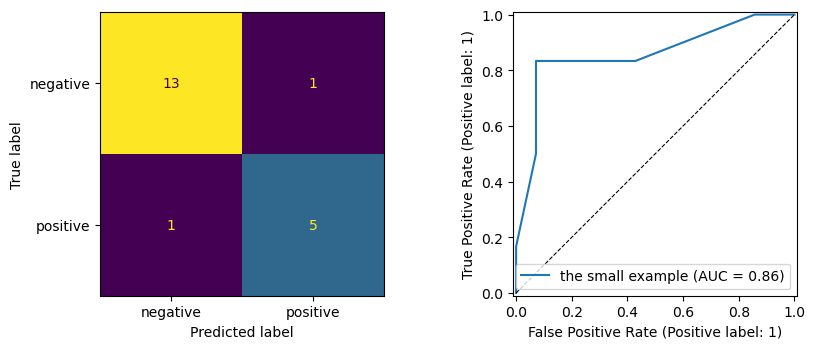

In [6]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

y_test, p_test = y_small, s_small
y_pred = p_test > 0.5
cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="the small example")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

## Exercise 2: MNIST, one digit against the rest

### The network of week 41

Replace by your Project 2 code; the only requirement is `predict` returning
a probability for the binary head and a row of class probabilities for the
softmax head.

In [7]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def accuracy(X, y, layers, hidden_activation, head):
    """Fraction of correct labels; y holds integer labels for softmax, 0/1 for binary."""
    out = predict(X, layers, hidden_activation, head)
    if head == "softmax":
        return np.mean(np.argmax(out, axis=1) == y)
    return np.mean((out[:, 0] > 0.5) == (y > 0.5))


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history


def one_hot(y, n_classes=None):
    """Integer labels -> one-hot rows."""
    n_classes = int(np.max(y)) + 1 if n_classes is None else n_classes
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y


def load_mnist():
    """The 70 000 MNIST images as (X_train, y_train, X_test, y_test), pixels scaled to [0, 1], 784 columns.

    Looks for the repository's mnist.npz first (no download needed) and falls
    back on scikit-learn's fetch_openml, which downloads 70 000 images once.
    """
    here = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
    candidates = [os.path.join(here, "mnist.npz"),
                  os.path.join(here, "..", "BookPrograms", "chapter10_convolutional_networks", "mnist.npz"),
                  os.path.join(here, "..", "..", "BookML", "BookPrograms", "chapter10_convolutional_networks", "mnist.npz")]
    for path in candidates:
        if os.path.exists(path):
            d = np.load(path)
            X_train = d["x_train"].reshape(len(d["x_train"]), -1).astype(float) / 255.0
            X_test = d["x_test"].reshape(len(d["x_test"]), -1).astype(float) / 255.0
            return X_train, d["y_train"].astype(int), X_test, d["y_test"].astype(int)
    from sklearn.datasets import fetch_openml
    mnist = fetch_openml("mnist_784", version=1, as_frame=False)
    X = mnist.data.astype(float) / 255.0
    y = mnist.target.astype(int)
    return X[:60000], y[:60000], X[60000:], y[60000:]


### a) The digit, the prevalence and the number to beat

We take $d=8$. The prevalence of eights in the test set and the accuracy of
"never an eight" are the two numbers every accuracy below is compared with.
(For another digit the prevalence is between $8.9\%$ for fives and $11.4\%$
for ones, and the majority rule scores one minus that.)

In [8]:
d = 8
x_train, digits_train, x_test, digits_test = load_mnist()      # flattened, scaled to [0, 1]
y_train = (digits_train == d).astype(float)
y_test = (digits_test == d).astype(float)
print(f"digit {d}: {int(y_train.sum())} of {len(y_train)} training images ({y_train.mean():.4f}), "
      f"{int(y_test.sum())} of {len(y_test)} test images ({y_test.mean():.4f})")
p0 = 1 - y_test.mean()
print(f"accuracy of 'never a {d}' on the test set: {p0:.4f}")

digit 8: 5851 of 60000 training images (0.0975), 974 of 10000 test images (0.0974)
accuracy of 'never a 8' on the test set: 0.9026


### b) Two classifiers, the confusion matrix at $t=0.5$

Logistic regression is the network with no hidden layer and the sigmoid
head (`sizes = [784, 1]`); the second classifier has one hidden layer of 32
ReLU units. Both are trained on the whole training set with SGD, $M=100$,
$\gamma=0.1$, ten epochs, seed 2026 — the settings of the Monday lecture.
No validation set this week: the test set is used once, at the end, with
the conventional threshold.

In [9]:
models = {}
for name, sizes, act in (("logistic regression", [784, 1], "sigmoid"),
                         ("one hidden layer of 32", [784, 32, 1], "relu")):
    t0 = time.time()
    layers = create_layers(sizes, act, np.random.default_rng(2026))
    layers, hist = train(x_train, y_train[:, None], layers, act, "binary", gamma=0.1, epochs=10,
                         batch_size=100, X_test=x_test, y_test=y_test)
    p = predict(x_test, layers, act, "binary")[:, 0]
    models[name] = {"layers": layers, "act": act, "p_test": p, "n_params": sum(W.size + b.size for W, b in layers)}
    r = classification_report(y_test, p > 0.5)
    models[name]["report"] = r
    print(f"--- {name}: {models[name]['n_params']} parameters, {time.time() - t0:.0f} s, final training cost {hist['cost'][-1]:.4f}")
    print(f"  confusion matrix (Eq. 5.67):  [[TP {r['TP']:4d}  FN {r['FN']:4d}]")
    print(f"                                 [FP {r['FP']:4d}  TN {r['TN']:4d}]]")
    print(f"  accuracy {r['accuracy']:.4f}  precision {r['precision']:.4f}  recall {r['recall']:.4f}  specificity {r['specificity']:.4f}  "
          f"F1 {r['f1']:.4f}  balanced {r['balanced_accuracy']:.4f}  MCC {r['mcc']:.4f}")
    print(f"  fraction of the remaining error removed: {1 - (1 - r['accuracy']) / (1 - p0):.3f}")
    print(f"  accuracy = pi*recall + (1-pi)*specificity = {y_test.mean() * r['recall'] + p0 * r['specificity']:.4f}")
    yp = p > 0.5
    print(f"  sklearn: {skm.confusion_matrix(y_test, yp).tolist()}  accuracy {skm.accuracy_score(y_test, yp):.4f} precision {skm.precision_score(y_test, yp):.4f} "
          f"recall {skm.recall_score(y_test, yp):.4f} F1 {skm.f1_score(y_test, yp):.4f}")

--- logistic regression: 785 parameters, 2 s, final training cost 0.1196
  confusion matrix (Eq. 5.67):  [[TP  703  FN  271]
                                 [FP  124  TN 8902]]
  accuracy 0.9605  precision 0.8501  recall 0.7218  specificity 0.9863  F1 0.7807  balanced 0.8540  MCC 0.7622
  fraction of the remaining error removed: 0.594
  accuracy = pi*recall + (1-pi)*specificity = 0.9605
  sklearn: [[8902, 124], [271, 703]]  accuracy 0.9605 precision 0.8501 recall 0.7218 F1 0.7807
--- one hidden layer of 32: 25153 parameters, 7 s, final training cost 0.0236
  confusion matrix (Eq. 5.67):  [[TP  885  FN   89]
                                 [FP   11  TN 9015]]
  accuracy 0.9900  precision 0.9877  recall 0.9086  specificity 0.9988  F1 0.9465  balanced 0.9537  MCC 0.9420
  fraction of the remaining error removed: 0.897
  accuracy = pi*recall + (1-pi)*specificity = 0.9900
  sklearn: [[9015, 11], [89, 885]]  accuracy 0.9900 precision 0.9877 recall 0.9086 F1 0.9465


--- one hidden layer of 32: 25153 parameters, 4 s, final training cost 0.0236
  confusion matrix (Eq. 5.67):  [[TP  885  FN   89]
                                 [FP   11  TN 9015]]
  accuracy 0.9900  precision 0.9877  recall 0.9086  specificity 0.9988  F1 0.9465  balanced 0.9537  MCC 0.9420
  fraction of the remaining error removed: 0.897
  accuracy = pi*recall + (1-pi)*specificity = 0.9900
  sklearn: [[9015, 11], [89, 885]]  accuracy 0.9900 precision 0.9877 recall 0.9086 F1 0.9465


**What the matrices say that the accuracies do not.** Both accuracies are
in the high nineties and both are above the majority rule, but the matrices
separate the two errors: logistic regression misses far more eights (FN)
than it raises false alarms (FP), so its recall is the number that is low,
while the one-hidden-layer network cuts the misses by more than half at a
similar number of false alarms. Written as
$\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$ with $\pi\approx0.10$,
both accuracies are carried by the specificity — which is why the
difference in recall barely shows in them. The honest comparison is the
fraction of the remaining error removed (printed above), or the pair of
matrices.

### c) ROC curves, AUCs and the output histograms

logistic regression: AUC trapezoid 0.96624, ranks 0.96624, sklearn 0.96624; 10001 points on the curve
one hidden layer of 32: AUC trapezoid 0.99795, ranks 0.99795, sklearn 0.99795; 10001 points on the curve


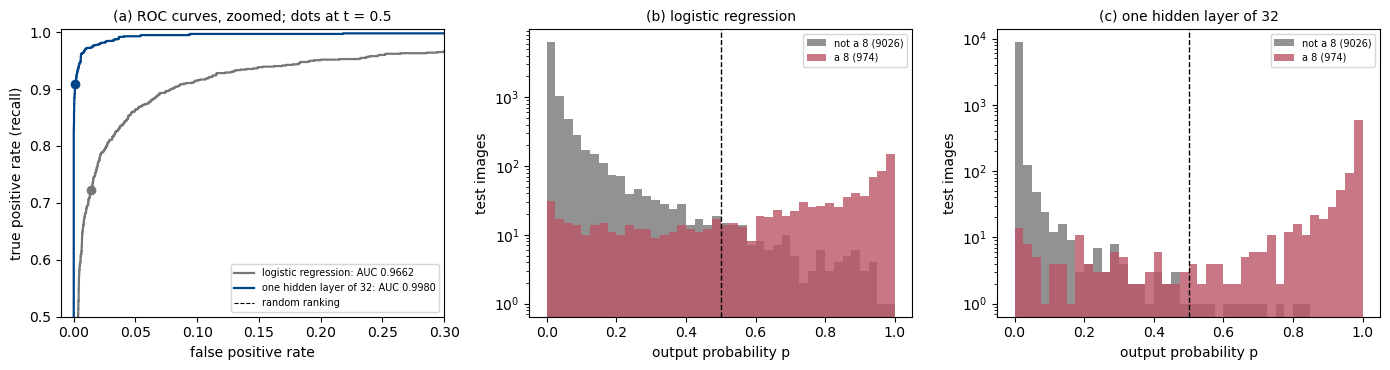

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
cols = {"logistic regression": GREY, "one hidden layer of 32": BLUE}
for name, m in models.items():
    p = m["p_test"]
    fpr, tpr, thr = roc_curve(y_test, p)
    m["auc"] = roc_auc(y_test, p)
    print(f"{name}: AUC trapezoid {auc_trapezoid(fpr, tpr):.5f}, ranks {m['auc']:.5f}, sklearn {skm.roc_auc_score(y_test, p):.5f}; "
          f"{len(fpr)} points on the curve")
    ax[0].plot(fpr, tpr, color=cols[name], lw=1.6, label=f"{name}: AUC {m['auc']:.4f}")
    k = np.searchsorted(-thr, -0.5)
    ax[0].plot(fpr[min(k, len(fpr) - 1)], tpr[min(k, len(tpr) - 1)], "o", color=cols[name], ms=6)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="random ranking")
ax[0].set_xlim(-0.01, 0.3); ax[0].set_ylim(0.5, 1.005)
ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate (recall)"); ax[0].legend(fontsize=7, loc="lower right")
ax[0].set_title(f"(a) ROC curves, zoomed; dots at t = 0.5", fontsize=10)
bins = np.linspace(0, 1, 41)
for a, name in zip(ax[1:], models):
    p = models[name]["p_test"]
    a.hist(p[y_test == 0], bins=bins, color=GREY, alpha=0.8, label=f"not a {d} ({int((y_test == 0).sum())})")
    a.hist(p[y_test == 1], bins=bins, color=RED, alpha=0.8, label=f"a {d} ({int(y_test.sum())})")
    a.axvline(0.5, color="k", ls="--", lw=1); a.set_yscale("log")
    a.set_xlabel("output probability p"); a.set_ylabel("test images"); a.legend(fontsize=7)
    a.set_title(f"({'bc'[list(models).index(name)]}) {name}", fontsize=10)
plt.tight_layout(); plt.show()

**Where the errors live, and what the AUCs add.** For both classifiers
most test images sit at $p\approx0$ or $p\approx1$; the errors are the thin
middle of the histograms, and for logistic regression that middle is much
fatter — many eights get probabilities between $0.1$ and $0.5$. The two
confusion matrices at $0.5$ compare the classifiers at one operating point;
the two AUCs compare their *rankings* at every operating point: the network
orders a random eight above a random non-eight with a higher probability
than logistic regression does, so no choice of threshold lets logistic
regression catch up — at any recall its false positive rate is higher. That
is what the matrices alone cannot say.

### d) Standard errors

An accuracy $\hat p$ measured on $n$ test images is a binomial proportion
with standard error $\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24); for the recall
the relevant $n$ is the number of positives, for the precision the number of
images flagged.

In [11]:
def se(p, n):
    return np.sqrt(p * (1 - p) / n)

n_pos = int(y_test.sum())
for name, m in models.items():
    r = m["report"]
    print(f"{name}: accuracy {r['accuracy']:.4f} ± {se(r['accuracy'], len(y_test)):.4f} (n = {len(y_test)}), "
          f"recall {r['recall']:.4f} ± {se(r['recall'], n_pos):.4f} (n = {n_pos}), "
          f"precision {r['precision']:.4f} ± {se(r['precision'], r['TP'] + r['FP']):.4f} (n = {r['TP'] + r['FP']})")
a1, a2 = models["logistic regression"]["report"]["accuracy"], models["one hidden layer of 32"]["report"]["accuracy"]
print(f"difference in accuracy {a2 - a1:.4f}, combined standard error {np.sqrt(se(a1, 10000)**2 + se(a2, 10000)**2):.4f}")
r1, r2 = models["logistic regression"]["report"]["recall"], models["one hidden layer of 32"]["report"]["recall"]
print(f"difference in recall {r2 - r1:.4f}, combined standard error {np.sqrt(se(r1, n_pos)**2 + se(r2, n_pos)**2):.4f}")

logistic regression: accuracy 0.9605 ± 0.0019 (n = 10000), recall 0.7218 ± 0.0144 (n = 974), precision 0.8501 ± 0.0124 (n = 827)
one hidden layer of 32: accuracy 0.9900 ± 0.0010 (n = 10000), recall 0.9086 ± 0.0092 (n = 974), precision 0.9877 ± 0.0037 (n = 896)
difference in accuracy 0.0295, combined standard error 0.0022
difference in recall 0.1869, combined standard error 0.0171


The differences are many standard errors wide, so they are not an artefact
of the particular 10 000 test images: the one-hidden-layer network is
better by any reasonable standard. (The two test sets are the same images,
so the two measurements are not independent and the combined standard error
is an upper bound on the error of the difference — if anything the
conclusion is stronger.)

## Exercise 3 (optional): ten classes — the matrix Project 2 asks for

### a) The $10\times10$ matrix by hand

The $784\to100\to10$ ReLU softmax network of weeks 41–43, twenty epochs,
seed 2026: test accuracy $0.9763$, as in the lectures. `np.add.at` builds
the matrix in one line; rows are the true digit, columns the predicted one.

In [12]:
def confusion_matrix_multiclass(y_true, y_pred, n_classes):
    """C[i, j] = number of samples of true class i predicted as class j."""
    C = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(C, (np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)), 1)
    return C


def per_class_from_confusion(C):
    """Precision and recall of every class from the K x K matrix: each class against the rest."""
    tp = np.diag(C).astype(float)
    precision = tp / np.maximum(C.sum(axis=0), 1)
    recall = tp / np.maximum(C.sum(axis=1), 1)
    return precision, recall


In [13]:
t0 = time.time()
layers10 = create_layers([784, 100, 10], "relu", np.random.default_rng(2026))
layers10, hist10 = train(x_train, one_hot(digits_train, 10), layers10, "relu", "softmax", gamma=0.1, epochs=20,
                         batch_size=100, X_test=x_test, y_test=digits_test)
P_test = predict(x_test, layers10, "relu", "softmax")
yhat = np.argmax(P_test, axis=1)
Cm = confusion_matrix_multiclass(digits_test, yhat, 10)
print(f"test accuracy {np.mean(yhat == digits_test):.4f} ({time.time() - t0:.0f} s); matrix identical to sklearn's: {np.array_equal(Cm, skm.confusion_matrix(digits_test, yhat))}")
print(Cm)

test accuracy 0.9763 (45 s); matrix identical to sklearn's: True
[[ 967    0    0    1    0    4    2    1    3    2]
 [   0 1123    4    0    0    1    2    1    4    0]
 [   4    1 1008    3    2    0    2    7    5    0]
 [   0    0    8  984    0    5    0    3    5    5]
 [   1    0    2    1  947    1    5    3    3   19]
 [   3    1    0    6    1  870    4    1    2    4]
 [   5    3    2    0    2    6  938    0    2    0]
 [   1    4   10    3    0    0    0 1000    2    8]
 [   3    0    4    7    4    4    3    3  943    3]
 [   3    2    1    6    5    1    0    5    3  983]]


### b) Per-class precision and recall, the confused pairs, and the $2\times2$ of the eights

The recall of class $i$ is row $i$ over its sum, the precision of class $j$
is column $j$ over its sum. The $2\times2$ matrix of "$d$ against the rest"
is read off the big one: TP $=C_{dd}$, FN $=$ the rest of row $d$, FP $=$
the rest of column $d$, TN $=$ everything else.

In [14]:
prec, rec = per_class_from_confusion(Cm)
print("per-class precision:", prec)
print("per-class recall:   ", rec)
rep = skm.classification_report(digits_test, yhat, digits=4, output_dict=True)
print("agree with sklearn's classification_report:",
      np.allclose(prec, [rep[str(k)]["precision"] for k in range(10)]) and np.allclose(rec, [rep[str(k)]["recall"] for k in range(10)]))
off = Cm.copy(); np.fill_diagonal(off, 0)
pairs = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
print("five most frequent confusions (true -> predicted: count): " + ", ".join(f"{i} -> {j}: {off[i, j]}" for i, j in pairs))
both = [f"{i}<->{j} ({off[i, j]}, {off[j, i]})" for i in range(10) for j in range(i + 1, 10) if off[i, j] >= 4 and off[j, i] >= 4]
print("confused in both directions (at least 4 each way; counts i->j, j->i):", ", ".join(both))
tp = Cm[d, d]; fn = Cm[d, :].sum() - tp; fp = Cm[:, d].sum() - tp; tn = Cm.sum() - tp - fn - fp
print(f"\n'{d} against the rest' from the 10x10 matrix: TP {tp} FN {fn} FP {fp} TN {tn}  precision {tp / (tp + fp):.4f} recall {tp / (tp + fn):.4f}")
for name, m in models.items():
    r = m["report"]
    print(f"binary classifier of exercise 2, {name}:           TP {r['TP']} FN {r['FN']} FP {r['FP']} TN {r['TN']}  precision {r['precision']:.4f} recall {r['recall']:.4f}")

per-class precision: [0.9797 0.9903 0.9702 0.9733 0.9854 0.9753 0.9812 0.9766 0.9702 0.96  ]
per-class recall:    [0.9867 0.9894 0.9767 0.9743 0.9644 0.9753 0.9791 0.9728 0.9682 0.9742]
agree with sklearn's classification_report: True
five most frequent confusions (true -> predicted: count): 4 -> 9: 19, 7 -> 2: 10, 3 -> 2: 8, 7 -> 9: 8, 8 -> 3: 7
confused in both directions (at least 4 each way; counts i->j, j->i): 2<->7 (7, 10), 2<->8 (5, 4), 3<->5 (5, 6), 3<->8 (5, 7), 3<->9 (5, 6), 4<->9 (19, 5), 5<->6 (4, 6), 7<->9 (8, 5)

'8 against the rest' from the 10x10 matrix: TP 943 FN 31 FP 29 TN 8997  precision 0.9702 recall 0.9682
binary classifier of exercise 2, logistic regression:           TP 703 FN 271 FP 124 TN 8902  precision 0.8501 recall 0.7218
binary classifier of exercise 2, one hidden layer of 32:           TP 885 FN 89 FP 11 TN 9015  precision 0.9877 recall 0.9086


**Same model? Same decision rule? Which is better?** Neither the model nor
the rule is the same. The softmax network was trained on all ten labels and
decides by $\arg\max_k p_k$ — an eight is declared when $p_8$ beats the
other nine probabilities, whatever its absolute value — while the binary
network saw only "eight or not" and decides by $p>0.5$. The two $2\times2$
matrices sit at different operating points: the ten-class network misses
far fewer eights (recall $0.97$ against $0.91$) but raises more false
alarms (precision $0.97$ against $0.99$), because $\arg\max$ is a more
permissive rule for a class than $p>0.5$ on a dedicated network, and
because the ten-class network must also keep the other nine classes apart.
By $F_1$ and by the number of errors ($60$ against $100$) the ten-class
network wins, helped by its hundred hidden units and by having learned what
the other nine digits look like. The lesson for Project 2 is that a
one-against-the-rest reading of the $10\times10$ matrix is a different
classifier from a one-against-the-rest network, and a report should say
which of the two it describes.

### c) The matrix as a picture

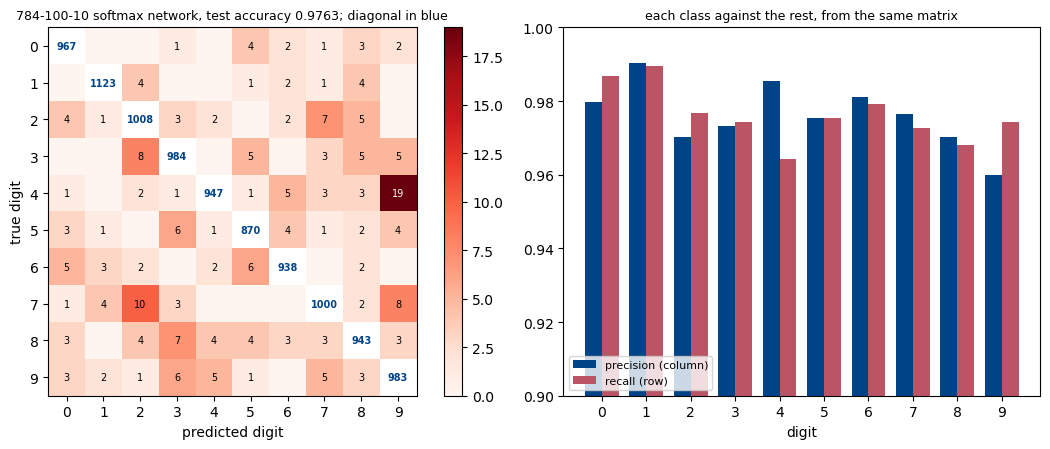

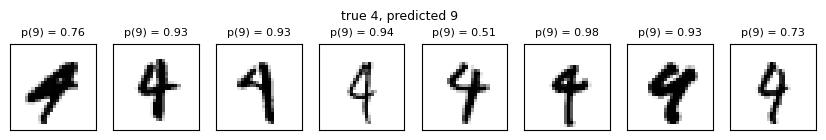

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
offn = off.astype(float); np.fill_diagonal(offn, np.nan)
im = ax[0].imshow(offn, cmap="Reds", vmin=0, vmax=np.nanmax(offn))
for i in range(10):
    for j in range(10):
        if i == j:
            ax[0].text(j, i, f"{Cm[i, j]}", ha="center", va="center", fontsize=7, color=BLUE, fontweight="bold")
        elif Cm[i, j] > 0:
            ax[0].text(j, i, f"{Cm[i, j]}", ha="center", va="center", fontsize=7, color="white" if Cm[i, j] > 0.6 * np.nanmax(offn) else "black")
ax[0].set_xticks(range(10)); ax[0].set_yticks(range(10)); ax[0].set_xlabel("predicted digit"); ax[0].set_ylabel("true digit")
ax[0].set_title(f"784-100-10 softmax network, test accuracy {np.mean(yhat == digits_test):.4f}; diagonal in blue", fontsize=9)
fig.colorbar(im, ax=ax[0], fraction=0.046)
w = 0.38
ax[1].bar(np.arange(10) - w / 2, prec, w, color=BLUE, label="precision (column)")
ax[1].bar(np.arange(10) + w / 2, rec, w, color=RED, label="recall (row)")
ax[1].set_ylim(0.9, 1.0); ax[1].set_xticks(range(10)); ax[1].set_xlabel("digit"); ax[1].legend(fontsize=8, loc="lower left")
ax[1].set_title("each class against the rest, from the same matrix", fontsize=9)
plt.tight_layout(); plt.show()

# a few of the confused images: the most frequent pair, true i predicted j
i, j = pairs[0]
idx = np.where((digits_test == i) & (yhat == j))[0][:8]
fig, ax = plt.subplots(1, len(idx), figsize=(1.3 * len(idx), 1.6))
for a, k in zip(np.atleast_1d(ax), idx):
    a.imshow(x_test[k].reshape(28, 28), cmap="gray_r"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"p({j}) = {P_test[k, j]:.2f}", fontsize=8)
fig.suptitle(f"true {i}, predicted {j}", fontsize=9)
plt.show()

Pairs that are confused in both directions are digits that share a
shape — a closed loop with a tail (4/9), a loop on a stroke (3/5, 3/8), a
bar with a hook (7/2, 7/9) — and some of the confused images above are
hard for a human too, while others are clearly readable and simply lie too
far from what the network has seen: a dense network has no notion of a
stroke being *displaced*, which is what next week's convolutional layers
address.

### d) Error bars, a second network, and how many test images

The test accuracy is a binomial proportion with standard error
$\sqrt{\hat p(1-\hat p)/n}$. We train a second network with a different seed
(same architecture) and a third with a different architecture, and ask
whether the differences exceed the error bars.

In [16]:
results = {"784-100-10, seed 2026": float(np.mean(yhat == digits_test))}
for label, sizes, seed in (("784-100-10, seed 1", [784, 100, 10], 1), ("784-50-10, seed 2026", [784, 50, 10], 2026)):
    L = create_layers(sizes, "relu", np.random.default_rng(seed))
    L, _ = train(x_train, one_hot(digits_train, 10), L, "relu", "softmax", gamma=0.1, epochs=20, batch_size=100)
    results[label] = float(np.mean(np.argmax(predict(x_test, L, "relu", "softmax"), axis=1) == digits_test))
for label, acc in results.items():
    print(f"{label:24s} test accuracy {acc:.4f} ± {se(acc, 10000):.4f}")
accs = list(results.values())
print(f"largest difference {max(accs) - min(accs):.4f}, against a combined standard error of about {np.sqrt(2) * se(0.976, 10000):.4f}")
p_hat = 0.97
for delta in (0.001,):
    n_needed = 2 * p_hat * (1 - p_hat) / delta**2        # two independent test sets, difference = 1 s.e.
    print(f"to resolve a difference of {100 * delta:.1f} points at {p_hat:.0%} accuracy at one standard error: n = {n_needed:.0f} images per test set; "
          f"at two standard errors: {4 * n_needed:.0f}")

784-100-10, seed 2026    test accuracy 0.9763 ± 0.0015
784-100-10, seed 1       test accuracy 0.9770 ± 0.0015
784-50-10, seed 2026     test accuracy 0.9731 ± 0.0016
largest difference 0.0039, against a combined standard error of about 0.0022
to resolve a difference of 0.1 points at 97% accuracy at one standard error: n = 58200 images per test set; at two standard errors: 232800


At $97\%$ accuracy on $10\,000$ images the standard error is $0.0016$.
Two seeds of the same architecture differ by less than one standard error
— that difference is noise; the hundred- against fifty-unit networks differ
by $0.4$ points, less than two combined standard errors, so even that
comparison is only suggestive on this test set. To resolve a difference of $0.1$ points at one standard error one needs
$2\hat p(1-\hat p)/\delta^2\approx58\,000$ images in each test set, and
four times that for two standard errors; the MNIST test set is far too
small for claims at that level, which is why the literature's "$99.1\%$
versus $99.2\%$" comparisons mean little unless averaged over many seeds.

## Discussion — the insights you should have gained

1. **Four counts, two kinds of error.** Everything (accuracy, precision,
   recall, specificity, $F_1$, balanced accuracy, MCC) is a function of TP,
   FN, FP, TN, and the matrix itself is the most informative thing to
   report; FN and FP are different errors with different costs.
2. **Accuracy is prevalence-weighted**:
   $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$. With $10\%$
   positives the misses enter with weight $0.1$, and an accuracy of $0.97$
   is compatible with missing a quarter of the positives. Always compare
   with the majority rule and quote the fraction of the remaining error
   removed.
3. **Recall is about the misses, precision about the false alarms** — two
   denominators, the truth and the decision — and they trade through the
   threshold. $F_1$ is small whenever either is small; MCC is the correlation
   of labels and decisions and is $0$ for the majority rule.
4. **The AUC is a probability about pairs**: that a random positive
   outscores a random negative. It judges the ranking, not a threshold, and
   it does not change if the positives are duplicated. It is what the matrix
   at $0.5$ cannot say: logistic regression and the network differ far more
   in their rankings than their accuracies suggest.
5. **One sorted pass gives the whole ROC curve**; the rank formula gives the
   area without the curve; ties need average ranks. Your functions should
   agree with `scikit-learn` to every digit — and then use `scikit-learn`.
6. **The $10\times10$ matrix** has recall along the rows and precision down
   the columns; a $2\times2$ read off it is a different classifier ($\arg\max$
   over ten probabilities, trained on ten labels) from a binary network, and
   the confused pairs are digits that share a shape.
7. **Every number has an error bar**, $\sqrt{\hat p(1-\hat p)/n}$; on
   10 000 images that is $\pm0.16$ points at $97\%$, which is about the
   seed-to-seed spread of one architecture. Differences inside the error bar
   are not differences.
8. **No validation set was used this week**, and that is a gap: the
   threshold, the architecture and the hyperparameters were all taken as
   given. Choosing them without touching the test set — cross-validation of
   your Project 2 network — is next week.